# CS781 Phase 3 — Rhetorical Role Prediction (CL and IT)

Self-contained Colab notebook using **your Phase 1 weights and tokenizer**, following the professor's
starter workflow: authenticate, download, prepare data, adapt model, train, evaluate, save, predict, ZIP.
Phase 3 §9 requires one official label per sentence, preserving document IDs and sentence order.
All official **train, dev, test** files from **both CL and IT** are downloaded and used:
train for fitting; labeled dev for model/decoder selection; unlabeled test for final predictions.

The six experiment options cover all four Phase 1 origins, four listed PEFT methods (LoRA, rsLoRA,
LoRMA+, IA³), and mandatory knowledge distillation, plus a full fine-tuning baseline.
The §1.4 six-submission minimum is stricter than §9.2's four-experiment description.
ZIP creation does not submit to Codabench; submit each distinct ZIP yourself.

Use a GPU runtime and a Colab secret named `HF`. Inputs: `MyDrive/cs781_phase1`.
Outputs: `MyDrive/cs781_phase3`. Section 3 contains **all tuning controls**; section 13 explains
controlled comparisons. No other pretrained LM or external LLM API is used. Keep your LLM declaration.
No score is promised: correctness checks and real dev performance are separate.

## 1. Install dependencies

In [ ]:
%pip -q install "tokenizers>=0.20,<0.24" "huggingface_hub>=0.26,<3" "tqdm>=4.66" "numpy>=1.26" "matplotlib>=3.8"

## 2. Mount Drive, authenticate, and check GPU

In [ ]:
import os, json, math, random, time, zipfile, hashlib, gc, copy, getpass, platform
from pathlib import Path
from contextlib import nullcontext
from collections import Counter
from bisect import bisect_left, bisect_right
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from tokenizers import ByteLevelBPETokenizer

try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive')
else:
    BASE_DIR = Path.cwd()

PHASE1_DIR = BASE_DIR / 'cs781_phase1' if IN_COLAB else BASE_DIR
PROJECT_DIR = BASE_DIR / 'cs781_phase3'
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.environ['HF_HOME'] = str(PROJECT_DIR / 'hf_cache')
from huggingface_hub import hf_hub_download, login

HF_TOKEN = os.environ.get('HF_TOKEN')
if IN_COLAB and not HF_TOKEN:
    try:
        HF_TOKEN = userdata.get('HF')
    except Exception:
        pass
def validate_hf_token(value):
    # Never print or include the credential in an error message.
    if not isinstance(value, str):
        raise TypeError('HF token must be a plain text string, not ' + type(value).__name__ + '.')
    value = value.strip()
    if not value.startswith('hf_'):
        raise ValueError('Paste only the Hugging Face personal access token starting with hf_.')
    return value

if HF_TOKEN:
    try:
        HF_TOKEN = validate_hf_token(HF_TOKEN)
    except (TypeError, ValueError) as error:
        print(str(error))
        HF_TOKEN = None
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Paste only your hf_ token (hidden): ')
HF_TOKEN = validate_hf_token(HF_TOKEN)
login(token=HF_TOKEN, add_to_git_credential=False)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP_DTYPE = torch.bfloat16 if DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float16
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
if DEVICE.type == 'cuda':
    print(torch.cuda.get_device_name(0))
else:
    print('CPU is suitable for checks; select a Colab GPU before full training.')
print('Phase 1 input:', PHASE1_DIR)
print('Phase 3 output:', PROJECT_DIR)

# Atomic writes avoid leaving partially written JSON/checkpoints after interruption.
def save_json(data, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')
    os.replace(temporary, path)

def save_torch(data, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    torch.save(data, temporary)
    os.replace(temporary, path)

def amp_context():
    return torch.autocast('cuda', dtype=AMP_DTYPE) if DEVICE.type == 'cuda' else nullcontext()

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(seed)

Mounted at /content/drive
Device: cuda | PyTorch: 2.11.0+cu130
NVIDIA RTX PRO 6000 Blackwell Server Edition
Phase 1 input: /content/drive/MyDrive/cs781_phase1
Phase 3 output: /content/drive/MyDrive/cs781_phase3


## 3. Configuration — change settings here

First run: `EXPERIMENT='decoder_full'`, `RUN_ALL=False`. For the six required options, use
`RUN_ALL=True`; the KD student runs last and chooses a completed teacher by combined dev macro-F1.
A single KD run needs at least one compatible completed non-KD run under the same `RUN_TAG`.

**Fresh experiment:** choose a new `RUN_TAG` when changing epochs, LR, batch size, context, rank,
loss weighting, or decoding settings. `RESUME=True` restores `last.pt` only for identical settings.
Completed runs skip training but regenerate verification and predictions.

Sentence context is text only; gold neighboring labels are never included as input. Both target-token
mean pooling and the final EOS representation are used, so causal models can also use following context.
The encoder–decoder origin uses its pretrained encoder; unused decoder and LM heads are removed only
after strict checkpoint loading. The student retains every second Phase 1 lightweight block.

In [ ]:
SEED = 42
EXPERIMENT = 'lightweight_kd'
RUN_ALL = False
RUN_TAG = 'kd_context2'
RESUME = True
HF_DATASET_REPO = 'Exploration-Lab/CS-781-Capstone'
EPOCHS = 6
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4
MAX_LENGTH = 384
MAX_TARGET_TOKENS = 256
CONTEXT_SENTENCES = 2  # 0 = sentence only; 1 = one previous + one following sentence.
HEAD_DROPOUT = 0.15
HEAD_LR_MULTIPLIER = 5.0
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.1
USE_CLASS_WEIGHTS = True
CLASS_WEIGHT_POWER = 0.5
MAX_CLASS_WEIGHT = 4.0
EARLY_STOPPING_PATIENCE = 3  # 0 disables stopping; checkpoint selection always uses dev F1.
ADAPTER_RANK = 8
ADAPTER_ALPHA = 16.0
KD_WEIGHT = 0.5
KD_TEMPERATURE = 2.0
GRADIENT_CHECKPOINTING = True
SAVE_EVERY_STEPS = 100
MAX_OPTIMIZER_STEPS = None  # Positive integer for smoke tests; leave None for real runs.
NUM_WORKERS = 0
OPTIMIZE_DECODING = True
SELECT_CHECKPOINT_WITH_DECODER = True
TRANSITION_STRENGTHS = [0.0, 0.1, 0.3, 0.6]
PRIOR_CORRECTIONS = [0.0, 0.25]  # Small dev-only search, fitted train priors.
PHASE1_HEADS = {'decoder_only': 12, 'encoder_decoder': 8, 'hybrid_prefixlm': 10, 'lightweight': 12}
EXPERIMENTS = {
    'decoder_full': {'architecture': 'decoder_only', 'method': 'full', 'lr': 3e-5},
    'encoder_ia3': {'architecture': 'encoder_decoder', 'method': 'ia3', 'lr': 3e-4},
    'hybrid_lora': {'architecture': 'hybrid_prefixlm', 'method': 'lora', 'lr': 2e-4},
    'lightweight_lorma': {'architecture': 'lightweight', 'method': 'lorma', 'lr': 2e-4},
    'hybrid_rslora': {'architecture': 'hybrid_prefixlm', 'method': 'rslora', 'lr': 2e-4},
    'lightweight_kd': {'architecture': 'lightweight', 'method': 'kd', 'lr': 5e-5},
}
TEACHER_EXPERIMENT = None  # None = strongest compatible, completed, larger teacher by dev F1.
assert EXPERIMENT in EXPERIMENTS
assert EPOCHS > 0 and BATCH_SIZE > 0 and GRAD_ACCUM_STEPS > 0
assert 0 <= CONTEXT_SENTENCES and 0 < MAX_TARGET_TOKENS <= MAX_LENGTH-4
assert MAX_LENGTH <= 1024 and SAVE_EVERY_STEPS > 0 and ADAPTER_RANK > 0
assert 0 <= KD_WEIGHT <= 1 and KD_TEMPERATURE > 0
assert 0 <= CLASS_WEIGHT_POWER <= 1 and MAX_CLASS_WEIGHT >= 1
assert EARLY_STOPPING_PATIENCE >= 0 and HEAD_LR_MULTIPLIER > 0
assert MAX_OPTIMIZER_STEPS is None or MAX_OPTIMIZER_STEPS > 0
seed_all(SEED)

## 4. Download all seven official files and verify train/dev/test schemas

In [ ]:
FILES = {'labels': 'Phase_3_RR/Train/label_vocab.json'}
for domain in ['CL', 'IT']:
    for split in ['train', 'dev', 'test']:
        folder = 'Test' if split == 'test' else 'Train'
        FILES[f'{domain}_{split}'] = f'Phase_3_RR/{folder}/{domain}_{split}.json'
local_files = {}
for key, filename in tqdm(FILES.items(), desc='Downloading RR data', unit='file'):
    local_files[key] = Path(hf_hub_download(repo_id=HF_DATASET_REPO, filename=filename,
                                         repo_type='dataset', token=HF_TOKEN))
EXPECTED_LABELS = ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute',
    'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled',
    'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']

def parse_label_vocab(data):
    if isinstance(data, dict):
        for key in ['label_to_id', 'label2id', 'id_to_label', 'id2label', 'labels']:
            if key in data:
                return parse_label_vocab(data[key])
        if set(data) == set(EXPECTED_LABELS):
            labels = sorted(data, key=lambda label: int(data[label]))
        elif all(isinstance(v, str) for v in data.values()):
            labels = [v for k, v in sorted(data.items(), key=lambda kv: int(kv[0]))]
        else:
            raise ValueError('Unsupported official label vocabulary format; inspect label_vocab.json.')
    elif isinstance(data, list) and all(isinstance(x, str) for x in data):
        labels = data
    else:
        raise ValueError('Official labels must be a list or an ID/label mapping.')
    if set(labels) != set(EXPECTED_LABELS) or len(labels) != 13:
        raise ValueError(f'Official label names differ from §9.3.6: {labels}')
    return labels

LABELS = parse_label_vocab(json.loads(local_files['labels'].read_text(encoding='utf-8-sig')))
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
NUM_LABELS = len(LABELS)
DOMAIN2ID = {'CL': 0, 'IT': 1}

def normalize_rr(data, domain, labeled):
    if isinstance(data, dict) and 'id' in data and 'text' in data:
        entries = [(str(data['id']), data)]
    elif isinstance(data, dict):
        entries = [(str(k), v) for k, v in data.items()]
    elif isinstance(data, list):
        entries = []
        for record in data:
            if not isinstance(record, dict) or 'id' not in record:
                raise ValueError('Expected document objects with id/text/labels, or a keyed mapping.')
            entries.append((str(record['id']), record))
    else:
        raise ValueError('Unsupported RR JSON top-level format.')
    result = {}
    for doc_id, record in entries:
        if isinstance(record, dict):
            if 'id' in record and str(record['id']) != doc_id:
                raise ValueError(f'Document ID mismatch: {doc_id}')
            sentences = record.get('text', record.get('sentences'))
            labels = record.get('labels') if labeled else None
        elif isinstance(record, list) and not labeled:
            sentences, labels = record, None
        else:
            raise ValueError(f'{doc_id}: expected document text and labels.')
        if not isinstance(sentences, list) or not all(isinstance(s, str) for s in sentences):
            raise ValueError(f'{doc_id}: sentences must be an ordered list of strings.')
        if labeled and (not isinstance(labels, list) or len(labels) != len(sentences)
                        or any(label not in LABEL2ID for label in labels)):
            raise ValueError(f'{doc_id}: invalid labels, names, or sentence-label count.')
        if doc_id in result:
            raise ValueError(f'Duplicate document ID {doc_id}')
        result[doc_id] = {'id': doc_id, 'domain': domain, 'text': sentences, 'labels': labels}
    return result

DATA = {split: {} for split in ['train', 'dev', 'test']}
for domain in ['CL', 'IT']:
    for split in DATA:
        records = normalize_rr(json.loads(local_files[f'{domain}_{split}'].read_text(encoding='utf-8-sig')),
                               domain, labeled=split != 'test')
        if set(DATA[split]) & set(records):
            raise ValueError('CL/IT IDs collide. A single prediction mapping cannot represent both; inspect official IDs.')
        DATA[split].update(records)
for a, b in [('train', 'dev'), ('train', 'test'), ('dev', 'test')]:
    if set(DATA[a]) & set(DATA[b]):
        raise ValueError(f'{a}/{b} document IDs overlap; inspect before training.')
    hashes_a = {hashlib.sha256(json.dumps(d['text'], ensure_ascii=False).encode()).hexdigest() for d in DATA[a].values()}
    hashes_b = {hashlib.sha256(json.dumps(d['text'], ensure_ascii=False).encode()).hexdigest() for d in DATA[b].values()}
    if hashes_a & hashes_b:
        raise ValueError(f'Duplicate document texts across {a}/{b}; prevent split leakage before training.')
DATA_FINGERPRINT = hashlib.sha256(json.dumps(DATA, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
for split, docs in DATA.items():
    print(split, ':', len(docs), 'documents;', sum(len(d['text']) for d in docs.values()), 'sentences')
    for domain in DOMAIN2ID:
        domain_docs = [d for d in docs.values() if d['domain'] == domain]
        print(' ', domain, len(domain_docs), 'documents;', sum(len(d['text']) for d in domain_docs), 'sentences')
        if not domain_docs or not sum(len(d['text']) for d in domain_docs):
            raise ValueError(f'Empty {domain} {split} data.')
        if split != 'test':
            print('  Labels:', dict(Counter(label for d in domain_docs for label in d['labels'])))
save_json({'labels': LABELS, 'files': FILES, 'data_fingerprint': DATA_FINGERPRINT}, PROJECT_DIR / 'dataset_manifest.json')

train : 80 documents; 16845 sentences
  CL 40 documents; 10593 sentences
  Labels: {'Fact': 2979, 'ArgumentPetitioner': 976, 'ArgumentRespondent': 996, 'RatioOfTheDecision': 2856, 'RulingByPresentCourt': 113, 'RulingByLowerCourt': 438, 'None': 53, 'PrecedentNotReliedUpon': 209, 'PrecedentReliedUpon': 1305, 'Statute': 367, 'Issue': 17, 'Dissent': 284}
  IT 40 documents; 6252 sentences
  Labels: {'Fact': 1119, 'RulingByLowerCourt': 436, 'ArgumentPetitioner': 637, 'Issue': 90, 'Statute': 732, 'RatioOfTheDecision': 1445, 'RulingByPresentCourt': 194, 'PrecedentReliedUpon': 640, 'ArgumentRespondent': 352, 'PrecedentNotReliedUpon': 360, 'None': 244, 'PrecedentOverruled': 3}
dev : 10 documents; 2142 sentences
  CL 5 documents; 1396 sentences
  Labels: {'Fact': 249, 'ArgumentPetitioner': 344, 'None': 2, 'ArgumentRespondent': 236, 'RatioOfTheDecision': 288, 'RulingByPresentCourt': 18, 'RulingByLowerCourt': 56, 'Issue': 3, 'Statute': 58, 'PrecedentReliedUpon': 142}
  IT 5 documents; 746 sentences

## 5. Load the exact Phase 1 tokenizer and build context-aware sentence examples

No sentence is skipped. Long targets keep head and tail tokens; truncation counts are reported.
Context budget follows the target budget. Empty sentences use UNK as their representation but retain
one output label. Original sentence lists and their ordering are never altered.

In [ ]:
TOKENIZER_DIR = PHASE1_DIR / 'bpe_tokenizer'
for filename in ['vocab.json', 'merges.txt']:
    if not (TOKENIZER_DIR / filename).is_file():
        raise FileNotFoundError(TOKENIZER_DIR / filename)
tok = ByteLevelBPETokenizer(str(TOKENIZER_DIR / 'vocab.json'), str(TOKENIZER_DIR / 'merges.txt'))
PAD_ID, BOS_ID, EOS_ID, UNK_ID, SEP_ID = [tok.token_to_id(t) for t in ['<pad>', '<bos>', '<eos>', '<unk>', '<sep>']]
if any(t is None for t in [PAD_ID, BOS_ID, EOS_ID, UNK_ID, SEP_ID]):
    raise ValueError('Phase 1 tokenizer special-token mismatch.')
VOCAB_SIZE_ACTUAL = tok.get_vocab_size()
TOKENIZER_HASH = hashlib.sha256(b''.join((TOKENIZER_DIR / f).read_bytes() for f in ['vocab.json', 'merges.txt'])).hexdigest()
import shutil
(PROJECT_DIR / 'bpe_tokenizer').mkdir(exist_ok=True)
for filename in ['vocab.json', 'merges.txt']:
    shutil.copy2(TOKENIZER_DIR / filename, PROJECT_DIR / 'bpe_tokenizer' / filename)

def head_tail(tokens, budget):
    if budget <= 0:
        return []
    if len(tokens) <= budget:
        return tokens
    first = (budget+1)//2
    return tokens[:first] + tokens[-(budget-first):] if budget-first else tokens[:first]

def sentence_example(doc, index, sentence_tokens):
    raw_target = sentence_tokens[index] or [UNK_ID]
    target = head_tail(raw_target, MAX_TARGET_TOKENS)
    before = [t for s in sentence_tokens[max(0, index-CONTEXT_SENTENCES):index] for t in s + [SEP_ID]]
    after = [t for s in sentence_tokens[index+1:index+1+CONTEXT_SENTENCES] for t in s + [SEP_ID]]
    budget = MAX_LENGTH - len(target) - 4
    left_budget = min(len(before), budget//2)
    right_budget = min(len(after), budget-left_budget)
    left_budget = min(len(before), budget-right_budget)
    left = before[-left_budget:] if left_budget else []
    right = after[:right_budget]
    ids = [BOS_ID] + left + [SEP_ID] + target + [SEP_ID] + right + [EOS_ID]
    target_start = 2+len(left)
    target_mask = [False]*len(ids)
    target_mask[target_start:target_start+len(target)] = [True]*len(target)
    assert len(ids) <= MAX_LENGTH and any(target_mask)
    return {'input_ids': ids, 'target_mask': target_mask,
            'domain': DOMAIN2ID[doc['domain']], 'position': index/max(1,len(doc['text'])-1),
            'label': LABEL2ID[doc['labels'][index]] if doc['labels'] is not None else -100,
            'doc_id': doc['id'], 'sentence_index': index, 'target_truncated': len(raw_target)>len(target)}

class RRDataset(Dataset):
    def __init__(self, docs, description):
        self.rows = []
        for doc in tqdm(docs.values(), desc=description, unit='doc'):
            sentence_tokens = [tok.encode(s, add_special_tokens=False).ids for s in doc['text']]
            self.rows.extend(sentence_example(doc, i, sentence_tokens) for i in range(len(doc['text'])))
        print(description, ':', len(self.rows), 'sentences;', sum(r['target_truncated'] for r in self.rows), 'targets truncated')
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        return self.rows[index]

def collate_rr(rows):
    length = max(len(r['input_ids']) for r in rows)
    ids = torch.full((len(rows), length), PAD_ID, dtype=torch.long)
    mask = torch.zeros_like(ids, dtype=torch.bool)
    target = torch.zeros_like(mask)
    for i, row in enumerate(rows):
        n = len(row['input_ids'])
        ids[i,:n] = torch.tensor(row['input_ids'])
        mask[i,:n] = True
        target[i,:n] = torch.tensor(row['target_mask'])
    return {'input_ids': ids, 'attention_mask': mask, 'target_mask': target,
            'domains': torch.tensor([r['domain'] for r in rows]),
            'positions': torch.tensor([r['position'] for r in rows], dtype=torch.float32),
            'labels': torch.tensor([r['label'] for r in rows]),
            'keys': [(r['doc_id'], r['sentence_index']) for r in rows]}

SETS = {split: RRDataset(docs, 'Preparing '+split) for split, docs in DATA.items()}

Preparing train:   0%|          | 0/80 [00:00<?, ?doc/s]

Preparing train : 16845 sentences; 46 targets truncated


Preparing dev:   0%|          | 0/10 [00:00<?, ?doc/s]

Preparing dev : 2142 sentences; 6 targets truncated


Preparing test:   0%|          | 0/10 [00:00<?, ?doc/s]

Preparing test : 2197 sentences; 10 targets truncated


## 6. Compatible Phase 1 model definitions — no pretraining is rerun

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        norm = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return norm * self.weight


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)


def build_rope_cache(seq_len, head_dim, device, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2, device=device).float() / head_dim))
    t = torch.arange(seq_len, device=device).float()
    freqs = torch.einsum("i,j->ij", t, inv_freq)
    emb = torch.cat((freqs, freqs), dim=-1)
    return emb.cos()[None, None, :, :], emb.sin()[None, None, :, :]


def apply_rope(q, k, cos, sin):
    q_ = (q * cos) + (rotate_half(q) * sin)
    k_ = (k * cos) + (rotate_half(k) * sin)
    return q_, k_


class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff, bias=False)
        self.w3 = nn.Linear(d_model, d_ff, bias=False)
        self.w2 = nn.Linear(d_ff, d_model, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, max_len):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head = n_head
        self.d_head = d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.register_buffer("mask", torch.tril(torch.ones(max_len, max_len)).bool(), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        att = att.masked_fill(~self.mask[:T, :T], float("-inf"))
        att = F.softmax(att, dim=-1)
        out = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class GPTBlock(nn.Module):
    def __init__(self, d_model, n_head, d_ff, max_len):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head, max_len)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class DecoderOnlyGPT(nn.Module):
    """Architecture 1: classic decoder-only Transformer LM."""

    def __init__(self, vocab_size, n_layer, n_embd, n_head, d_ff, max_len=2048):
        super().__init__()
        self.max_len = max_len
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(max_len, n_embd)
        self.blocks = nn.ModuleList([GPTBlock(n_embd, n_head, d_ff, max_len) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight  # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, labels=None):
        B, T = input_ids.shape
        pos = torch.arange(T, device=input_ids.device).unsqueeze(0)
        x = self.tok_emb(input_ids) + self.pos_emb(pos)
        for blk in self.blocks:
            x = blk(x)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if labels is not None:
            loss = F.cross_entropy(
                logits[:, :-1].reshape(-1, logits.size(-1)),
                labels[:, 1:].reshape(-1),
                ignore_index=PAD_ID,
            )
        return loss, logits

    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.8, top_p=0.95):
        # Simplified, non-KV-cached generation (recomputes full forward pass each step).
        # Positions are re-based to 0 each call since context is re-clipped to max_len.
        self.eval()
        for _ in range(max_new_tokens):
            ids_cond = input_ids[:, -self.max_len:]
            _, logits = self(ids_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p).float().argmax(dim=-1, keepdim=True)
            keep_mask = torch.arange(sorted_probs.size(-1), device=probs.device).unsqueeze(0) > cutoff
            sorted_probs = sorted_probs.masked_fill(keep_mask, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            input_ids = torch.cat([input_ids, next_id], dim=1)
        return input_ids

In [ ]:
class RelativePositionBias(nn.Module):
    def __init__(self, n_head, num_buckets=32, max_distance=128, bidirectional=True):
        super().__init__()
        self.num_buckets = num_buckets
        self.max_distance = max_distance
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(num_buckets, n_head)

    @staticmethod
    def _bucket(rel_pos, bidirectional, num_buckets, max_distance):
        ret = 0
        n = -rel_pos
        if bidirectional:
            num_buckets //= 2
            ret += (n < 0).long() * num_buckets
            n = torch.abs(n)
        else:
            n = torch.clamp(n, min=0)
        max_exact = num_buckets // 2
        is_small = n < max_exact
        val_large = max_exact + (
            torch.log(n.float() / max_exact + 1e-6) / math.log(max_distance / max_exact) * (num_buckets - max_exact)
        ).long()
        val_large = torch.clamp(val_large, max=num_buckets - 1)
        ret = ret + torch.where(is_small, n, val_large)
        return ret

    def forward(self, q_len, k_len, device):
        q_pos = torch.arange(q_len, device=device)[:, None]
        k_pos = torch.arange(k_len, device=device)[None, :]
        rel_pos = k_pos - q_pos
        buckets = self._bucket(rel_pos, self.bidirectional, self.num_buckets, self.max_distance)
        values = self.embedding(buckets)                    # (q_len, k_len, n_head)
        return values.permute(2, 0, 1).unsqueeze(0)          # (1, n_head, q_len, k_len)


class RelPosAttention(nn.Module):
    def __init__(self, d_model, n_head):
        super().__init__()
        self.n_head = n_head
        self.d_head = d_model // n_head
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.o_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x_q, x_kv, bias=None, causal=False, key_padding_mask=None):
        B, Tq, C = x_q.shape
        Tk = x_kv.shape[1]
        q = self.q_proj(x_q).view(B, Tq, self.n_head, self.d_head).transpose(1, 2)
        k = self.k_proj(x_kv).view(B, Tk, self.n_head, self.d_head).transpose(1, 2)
        v = self.v_proj(x_kv).view(B, Tk, self.n_head, self.d_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        if bias is not None:
            att = att + bias
        if causal:
            causal_mask = torch.tril(torch.ones(Tq, Tk, device=x_q.device)).bool()
            att = att.masked_fill(~causal_mask, float("-inf"))
        if key_padding_mask is not None:
            pad_keep = key_padding_mask[:, None, None, :].bool()   # (B,1,1,Tk), 1 = keep
            att = att.masked_fill(~pad_keep, float("-inf"))
        att = F.softmax(att, dim=-1)
        out = (att @ v).transpose(1, 2).contiguous().view(B, Tq, C)
        return self.o_proj(out)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_head, d_ff):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = RelPosAttention(d_model, n_head)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x, bias, key_padding_mask):
        h = self.ln1(x)
        x = x + self.attn(h, h, bias=bias, causal=False, key_padding_mask=key_padding_mask)
        x = x + self.ff(self.ln2(x))
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_head, d_ff):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.self_attn = RelPosAttention(d_model, n_head)
        self.ln2 = nn.LayerNorm(d_model)
        self.cross_attn = RelPosAttention(d_model, n_head)
        self.ln3 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x, enc_out, self_bias, enc_padding_mask):
        h = self.ln1(x)
        x = x + self.self_attn(h, h, bias=self_bias, causal=True)
        x = x + self.cross_attn(self.ln2(x), enc_out, bias=None, causal=False, key_padding_mask=enc_padding_mask)
        x = x + self.ff(self.ln3(x))
        return x


class EncoderDecoderTransformer(nn.Module):
    """Architecture 2: T5-style encoder-decoder Transformer with relative position bias."""

    def __init__(self, vocab_size, n_enc_layer, n_dec_layer, d_model, n_head, d_ff):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.enc_layers = nn.ModuleList([EncoderLayer(d_model, n_head, d_ff) for _ in range(n_enc_layer)])
        self.dec_layers = nn.ModuleList([DecoderLayer(d_model, n_head, d_ff) for _ in range(n_dec_layer)])
        self.enc_rel_bias = RelativePositionBias(n_head, bidirectional=True)
        self.dec_rel_bias = RelativePositionBias(n_head, bidirectional=False)
        self.ln_enc_f = nn.LayerNorm(d_model)
        self.ln_dec_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def encode(self, src_ids, src_mask):
        x = self.tok_emb(src_ids)
        bias = self.enc_rel_bias(src_ids.size(1), src_ids.size(1), src_ids.device)
        for layer in self.enc_layers:
            x = layer(x, bias, src_mask)
        return self.ln_enc_f(x)

    def forward(self, src_ids, src_mask, tgt_in, tgt_out=None):
        enc_out = self.encode(src_ids, src_mask)
        x = self.tok_emb(tgt_in)
        bias = self.dec_rel_bias(tgt_in.size(1), tgt_in.size(1), tgt_in.device)
        for layer in self.dec_layers:
            x = layer(x, enc_out, bias, src_mask)
        x = self.ln_dec_f(x)
        logits = self.head(x)
        loss = None
        if tgt_out is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1), ignore_index=PAD_ID)
        return loss, logits

    @torch.no_grad()
    def generate(self, src_ids, src_mask, max_new_tokens, bos_id, eos_id, temperature=0.8, top_p=0.95):
        # Simplified, non-KV-cached autoregressive decoding.
        self.eval()
        enc_out = self.encode(src_ids, src_mask)
        B = src_ids.size(0)
        tgt = torch.full((B, 1), bos_id, dtype=torch.long, device=src_ids.device)
        for _ in range(max_new_tokens):
            x = self.tok_emb(tgt)
            bias = self.dec_rel_bias(tgt.size(1), tgt.size(1), tgt.device)
            h = x
            for layer in self.dec_layers:
                h = layer(h, enc_out, bias, src_mask)
            h = self.ln_dec_f(h)
            logits = self.head(h)[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p).float().argmax(dim=-1, keepdim=True)
            keep_mask = torch.arange(sorted_probs.size(-1), device=probs.device).unsqueeze(0) > cutoff
            sorted_probs = sorted_probs.masked_fill(keep_mask, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            tgt = torch.cat([tgt, next_id], dim=1)
        return tgt

In [ ]:
class RoPEAttention(nn.Module):
    def __init__(self, d_model, n_head):
        super().__init__()
        self.n_head = n_head
        self.d_head = d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, attn_mask, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        q, k = apply_rope(q, k, cos, sin)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        att = att.masked_fill(~attn_mask, float("-inf"))
        att = F.softmax(att, dim=-1)
        out = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class HybridBlock(nn.Module):
    def __init__(self, d_model, n_head, d_ff):
        super().__init__()
        self.norm1 = RMSNorm(d_model)
        self.attn = RoPEAttention(d_model, n_head)
        self.norm2 = RMSNorm(d_model)
        self.ff = SwiGLU(d_model, d_ff)

    def forward(self, x, attn_mask, cos, sin):
        x = x + self.attn(self.norm1(x), attn_mask, cos, sin)
        x = x + self.ff(self.norm2(x))
        return x


def build_prefix_lm_mask(prompt_len, total_len, device):
    """prompt<->prompt: bidirectional. continuation->prompt: visible.
    continuation<->continuation: causal."""
    mask = torch.zeros(total_len, total_len, dtype=torch.bool, device=device)
    mask[:prompt_len, :prompt_len] = True
    mask[prompt_len:, :prompt_len] = True
    cont_len = total_len - prompt_len
    if cont_len > 0:
        mask[prompt_len:, prompt_len:] = torch.tril(torch.ones(cont_len, cont_len, device=device)).bool()
    return mask


class HybridPrefixLM(nn.Module):
    """Architecture 3: single-stack encoder/hybrid LM (RoPE, RMSNorm, SwiGLU,
    UniLM-style prefix-bidirectional + causal-continuation attention mask)."""

    def __init__(self, vocab_size, n_layer, d_model, n_head, d_ff, max_len=1536):
        super().__init__()
        self.d_model = d_model
        self.n_head = n_head
        self.max_len = max_len
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([HybridBlock(d_model, n_head, d_ff) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, input_ids, prompt_len, labels=None):
        B, T = input_ids.shape
        x = self.tok_emb(input_ids)
        cos, sin = build_rope_cache(T, self.d_model // self.n_head, input_ids.device)
        mask = build_prefix_lm_mask(prompt_len, T, input_ids.device).unsqueeze(0).unsqueeze(0)
        for blk in self.blocks:
            x = blk(x, mask, cos, sin)
        x = self.norm_f(x)
        logits = self.head(x)
        loss = None
        if labels is not None:
            loss = F.cross_entropy(
                logits[:, :-1].reshape(-1, logits.size(-1)),
                labels[:, 1:].reshape(-1),
                ignore_index=PAD_ID,
            )
        return loss, logits

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens, temperature=0.8, top_p=0.95):
        self.eval()
        input_ids = prompt_ids
        prompt_len = prompt_ids.size(1)
        for _ in range(max_new_tokens):
            ids_cond = input_ids[:, -self.max_len:]
            cur_prompt_len = min(prompt_len, ids_cond.size(1))
            _, logits = self(ids_cond, cur_prompt_len)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p).float().argmax(dim=-1, keepdim=True)
            keep_mask = torch.arange(sorted_probs.size(-1), device=probs.device).unsqueeze(0) > cutoff
            sorted_probs = sorted_probs.masked_fill(keep_mask, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            input_ids = torch.cat([input_ids, next_id], dim=1)
        return input_ids

In [ ]:
class GQAAttention(nn.Module):
    """Grouped-Query Attention: n_kv_head < n_head, reducing parameters and
    (at inference, with KV caching) memory -- the key efficiency trick here."""

    def __init__(self, d_model, n_head, n_kv_head):
        super().__init__()
        assert n_head % n_kv_head == 0
        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.n_rep = n_head // n_kv_head
        self.d_head = d_model // n_head
        self.q_proj = nn.Linear(d_model, n_head * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_head * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_head * self.d_head, bias=False)
        self.o_proj = nn.Linear(n_head * self.d_head, d_model, bias=False)

    def forward(self, x, causal_mask, cos, sin):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_head, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_head, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_head, self.d_head).transpose(1, 2)
        q, k = apply_rope(q, k, cos, sin)
        k = k.repeat_interleave(self.n_rep, dim=1)
        v = v.repeat_interleave(self.n_rep, dim=1)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        att = att.masked_fill(~causal_mask, float("-inf"))
        att = F.softmax(att, dim=-1)
        out = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.o_proj(out)


class LightweightBlock(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, d_ff):
        super().__init__()
        self.norm1 = RMSNorm(d_model)
        self.attn = GQAAttention(d_model, n_head, n_kv_head)
        self.norm2 = RMSNorm(d_model)
        self.ff = SwiGLU(d_model, d_ff)

    def forward(self, x, mask, cos, sin):
        x = x + self.attn(self.norm1(x), mask, cos, sin)
        x = x + self.ff(self.norm2(x))
        return x


class LightweightLlama(nn.Module):
    """Architecture 4: efficient/lightweight decoder-only Transformer
    (RoPE, RMSNorm, SwiGLU, Grouped-Query Attention)."""

    def __init__(self, vocab_size, n_layer, d_model, n_head, n_kv_head, d_ff, max_len=2048):
        super().__init__()
        self.d_model = d_model
        self.n_head = n_head
        self.max_len = max_len
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([LightweightBlock(d_model, n_head, n_kv_head, d_ff) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, input_ids, labels=None):
        B, T = input_ids.shape
        x = self.tok_emb(input_ids)
        cos, sin = build_rope_cache(T, self.d_model // self.n_head, input_ids.device)
        mask = torch.tril(torch.ones(T, T, device=input_ids.device)).bool().unsqueeze(0).unsqueeze(0)
        for blk in self.blocks:
            x = blk(x, mask, cos, sin)
        x = self.norm_f(x)
        logits = self.head(x)
        loss = None
        if labels is not None:
            loss = F.cross_entropy(
                logits[:, :-1].reshape(-1, logits.size(-1)),
                labels[:, 1:].reshape(-1),
                ignore_index=PAD_ID,
            )
        return loss, logits

    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.8, top_p=0.95):
        self.eval()
        for _ in range(max_new_tokens):
            ids_cond = input_ids[:, -self.max_len:]
            _, logits = self(ids_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p).float().argmax(dim=-1, keepdim=True)
            keep_mask = torch.arange(sorted_probs.size(-1), device=probs.device).unsqueeze(0) > cutoff
            sorted_probs = sorted_probs.masked_fill(keep_mask, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            input_ids = torch.cat([input_ids, next_id], dim=1)
        return input_ids

## 7. Sentence classifier, Phase 1 loading, and adaptation methods

In [ ]:
def torch_load(path):
    return torch.load(path, map_location='cpu', weights_only=True)

def infer_phase1_config(architecture, state):
    vocab, dim = state['tok_emb.weight'].shape
    if vocab != VOCAB_SIZE_ACTUAL:
        raise ValueError(f'Phase 1 vocabulary {vocab} != tokenizer {VOCAB_SIZE_ACTUAL}')
    config = {'vocab_size': vocab}
    def count_layers(prefix):
        return len({int(k.split('.')[1]) for k in state if k.startswith(prefix + '.')})
    heads = PHASE1_HEADS[architecture]
    if architecture == 'decoder_only':
        config.update(n_layer=count_layers('blocks'), n_embd=dim, n_head=heads,
                      d_ff=state['blocks.0.mlp.0.weight'].shape[0], max_len=state['pos_emb.weight'].shape[0])
    elif architecture == 'encoder_decoder':
        stored_heads = state['enc_rel_bias.embedding.weight'].shape[1]
        if heads != stored_heads:
            raise ValueError('Encoder head count differs from stored relative-position bias.')
        config.update(n_enc_layer=count_layers('enc_layers'), n_dec_layer=count_layers('dec_layers'),
                      d_model=dim, n_head=heads, d_ff=state['enc_layers.0.ff.0.weight'].shape[0])
    elif architecture == 'hybrid_prefixlm':
        config.update(n_layer=count_layers('blocks'), d_model=dim, n_head=heads,
                      d_ff=state['blocks.0.ff.w1.weight'].shape[0], max_len=1152)
    else:
        head_dim = dim // heads
        config.update(n_layer=count_layers('blocks'), d_model=dim, n_head=heads,
                      n_kv_head=state['blocks.0.attn.k_proj.weight'].shape[0] // head_dim,
                      d_ff=state['blocks.0.ff.w1.weight'].shape[0], max_len=1024)
    if dim % heads:
        raise ValueError('Invalid Phase 1 attention head count.')
    return config

MODEL_CLASSES = {'decoder_only': DecoderOnlyGPT, 'encoder_decoder': EncoderDecoderTransformer,
                 'hybrid_prefixlm': HybridPrefixLM, 'lightweight': LightweightLlama}

def load_phase1(architecture):
    path = PHASE1_DIR / f'run_{architecture}' / 'final_model.pt'
    if not path.is_file():
        raise FileNotFoundError(f'Missing Phase 1 weights: {path}')
    print('Loading:', path)
    state = torch_load(path)
    config = infer_phase1_config(architecture, state)
    print('Inferred config:', config)
    backbone = MODEL_CLASSES[architecture](**config)
    backbone.load_state_dict(state, strict=True)
    del state
    gc.collect()
    original_parameters = sum(p.numel() for p in backbone.parameters())
    del backbone.head
    if architecture == 'encoder_decoder':
        del backbone.dec_layers, backbone.dec_rel_bias, backbone.ln_dec_f
    return backbone, config, original_parameters

class LegalRR(nn.Module):
    def __init__(self, backbone, architecture):
        super().__init__()
        self.backbone = backbone
        self.architecture = architecture
        self.dropout = nn.Dropout(HEAD_DROPOUT)
        dim = backbone.tok_emb.embedding_dim
        self.domain_embedding = nn.Embedding(2, 16)
        self.position_projection = nn.Linear(1, 8)
        self.classifier = nn.Sequential(nn.LayerNorm(2*dim+24), nn.Linear(2*dim+24, dim),
                                        nn.GELU(), nn.Dropout(HEAD_DROPOUT), nn.Linear(dim, NUM_LABELS))
        self.use_checkpointing = GRADIENT_CHECKPOINTING

    def layer_call(self, layer, *args):
        if self.training and self.use_checkpointing and any(p.requires_grad for p in layer.parameters()):
            return checkpoint(layer, *args, use_reentrant=False)
        return layer(*args)

    def forward(self, input_ids, attention_mask, target_mask, domains, positions):
        b = self.backbone
        length = input_ids.size(1)
        x = b.tok_emb(input_ids)
        if self.architecture == 'decoder_only':
            if length > b.max_len:
                raise ValueError('MAX_LENGTH exceeds Phase 1 positional embedding length.')
            x = x + b.pos_emb(torch.arange(length, device=input_ids.device)[None, :])
            for layer in b.blocks:
                x = self.layer_call(layer, x)
            x = b.ln_f(x)
        elif self.architecture == 'encoder_decoder':
            bias = b.enc_rel_bias(length, length, input_ids.device)
            for layer in b.enc_layers:
                x = self.layer_call(layer, x, bias, attention_mask)
            x = b.ln_enc_f(x)
        else:
            cos, sin = build_rope_cache(length, b.d_model // b.n_head, input_ids.device)
            if self.architecture == 'hybrid_prefixlm':
                # All text is a bidirectional prefix; mask PAD keys explicitly.
                mask = attention_mask[:, None, None, :].expand(-1, 1, length, -1)
            else:
                causal = torch.ones(length, length, dtype=torch.bool, device=input_ids.device).tril()
                mask = causal[None, None, :, :] & attention_mask[:, None, None, :]
            for layer in b.blocks:
                x = self.layer_call(layer, x, mask, cos, sin)
            x = b.norm_f(x)
        target_weights = (target_mask & attention_mask).to(x.dtype)
        pooled = (x * target_weights[:, :, None]).sum(1) / target_weights.sum(1, keepdim=True).clamp_min(1)
        final_index = attention_mask.sum(1)-1
        final = x[torch.arange(x.size(0), device=x.device), final_index]
        features = torch.cat([pooled, final, self.domain_embedding(domains),
                              self.position_projection(positions[:,None])], dim=-1)
        return self.classifier(self.dropout(features))

In [ ]:
class LowRankLinear(nn.Module):
    def __init__(self, base, method, rank=ADAPTER_RANK, alpha=ADAPTER_ALPHA):
        super().__init__()
        self.base = base
        self.method = method
        self.scale = alpha / (math.sqrt(rank) if method == 'rslora' else rank)
        self.base.requires_grad_(False)
        a_dim = base.out_features if method == 'lorma' else base.in_features
        self.A = nn.Linear(a_dim, rank, bias=False)
        self.B = nn.Linear(rank, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5))
        nn.init.zeros_(self.B.weight)
    def forward(self, x):
        if self.method != 'lorma':
            return self.base(x) + self.scale*self.B(self.A(x))
        wx = F.linear(x, self.base.weight, None)
        y = wx + self.scale*self.B(self.A(wx))
        return y if self.base.bias is None else y+self.base.bias

class IA3Linear(nn.Module):
    def __init__(self, base, mode):
        super().__init__()
        self.base = base
        self.mode = mode
        base.requires_grad_(False)
        size = base.in_features if mode == 'input' else base.out_features
        if mode == 'qkv':
            size = 2*base.out_features//3
        self.scale = nn.Parameter(torch.ones(size))
    def forward(self, x):
        if self.mode == 'input':
            return self.base(x*self.scale)
        y = self.base(x)
        if self.mode == 'qkv':
            q, kv = y.split([y.size(-1)//3, 2*y.size(-1)//3], dim=-1)
            return torch.cat([q, kv*self.scale], dim=-1)
        return y*self.scale

def configure_adaptation(model, method):
    model.backbone.requires_grad_(method in ['full', 'kd'])
    targets = []
    if method in ['lora', 'rslora', 'lorma', 'ia3']:
        for name, child in list(model.backbone.named_modules()):
            if not isinstance(child, nn.Linear):
                continue
            leaf = name.rsplit('.',1)[-1]
            attention = '.attn.' in name
            mode = None
            if method == 'ia3':
                if attention and leaf in ['k_proj','v_proj']:
                    mode = 'output'
                elif attention and leaf == 'qkv':
                    mode = 'qkv'
                elif name.endswith('.ff.w2') or name.endswith('.ff.2') or name.endswith('.mlp.2'):
                    mode = 'input'
            elif attention and leaf in ['qkv','proj','q_proj','k_proj','v_proj','o_proj']:
                mode = 'lowrank'
            if mode:
                parent, leaf = name.rsplit('.',1)
                wrapped = LowRankLinear(child, method) if mode == 'lowrank' else IA3Linear(child, mode)
                setattr(model.backbone.get_submodule(parent), leaf, wrapped)
                targets.append(name)
        if not targets:
            raise ValueError('No adaptation projections matched.')
    return targets

def make_model(spec):
    backbone, config, original_parameters = load_phase1(spec['architecture'])
    selected_layers = None
    if spec['method'] == 'kd':
        selected_layers = list(range(0,len(backbone.blocks),2))
        backbone.blocks = nn.ModuleList([backbone.blocks[i] for i in selected_layers])
    model = LegalRR(backbone, spec['architecture'])
    targets = configure_adaptation(model, spec['method'])
    metadata = {'phase1_config': config, 'phase1_parameters': original_parameters,
        'selected_phase1_layers': selected_layers, 'adapter_targets': targets,
        'total_parameters': sum(p.numel() for p in model.parameters()),
        'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad)}
    return model, metadata

def forward_batch(model, batch):
    return model(*[batch[key].to(DEVICE) for key in ['input_ids','attention_mask','target_mask','domains','positions']])

## 8. Official metric family, domain reports, and document-order verification

In [ ]:
def validate_predictions(predictions, docs):
    if set(predictions) != set(docs):
        raise ValueError('Missing or extra official document IDs.')
    for doc_id, doc in docs.items():
        labels = predictions[doc_id]
        if not isinstance(labels, list) or len(labels) != len(doc['text']):
            raise ValueError(f'{doc_id}: expected exactly one label per sentence.')
        if any(label not in LABEL2ID for label in labels):
            raise ValueError(f'{doc_id}: invalid label spelling or capitalization.')

def rr_metrics(predictions, docs):
    validate_predictions(predictions, docs)
    confusion = np.zeros((NUM_LABELS, NUM_LABELS), dtype=np.int64)
    for doc_id, doc in docs.items():
        if doc['labels'] is None:
            raise ValueError('Cannot score unlabeled official test data.')
        for reference, predicted in zip(doc['labels'], predictions[doc_id]):
            confusion[LABEL2ID[reference], LABEL2ID[predicted]] += 1
    per_label = {}
    for i, label in enumerate(LABELS):
        tp = int(confusion[i,i]); fp = int(confusion[:,i].sum()-tp); fn = int(confusion[i,:].sum()-tp)
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
        per_label[label] = {'precision': precision, 'recall': recall, 'f1': f1,
                            'tp': tp, 'fp': fp, 'fn': fn, 'support': tp+fn}
    assert int(confusion.sum()) == sum(len(d['text']) for d in docs.values())
    return {'macro_f1': sum(x['f1'] for x in per_label.values())/NUM_LABELS,
            'macro_precision': sum(x['precision'] for x in per_label.values())/NUM_LABELS,
            'macro_recall': sum(x['recall'] for x in per_label.values())/NUM_LABELS,
            'accuracy': float(np.trace(confusion)/max(1,confusion.sum())),
            'per_label': per_label, 'confusion_matrix': confusion.tolist(), 'sentence_count': int(confusion.sum())}

def all_metrics(predictions, docs):
    report = rr_metrics(predictions, docs)
    report['domains'] = {}
    for domain in DOMAIN2ID:
        subset = {k:d for k,d in docs.items() if d['domain'] == domain}
        report['domains'][domain] = rr_metrics({k:predictions[k] for k in subset}, subset)
    report['domain_mean_macro_f1'] = sum(x['macro_f1'] for x in report['domains'].values())/2
    return report

def show_scores(metrics, title):
    print(title)
    print(f"Macro-F1 [PRIMARY]: {metrics['macro_f1']:.6f}; Macro-Precision: {metrics['macro_precision']:.6f}; Macro-Recall: {metrics['macro_recall']:.6f}")
    print(f"{'Label':28s} {'Precision':>10s} {'Recall':>10s} {'F1':>10s} {'Gold':>8s}")
    for label in LABELS:
        r = metrics['per_label'][label]
        print(f"{label:28s} {r['precision']:10.4f} {r['recall']:10.4f} {r['f1']:10.4f} {r['support']:8d}")
    for domain, r in metrics.get('domains',{}).items():
        print(domain, f"macro-F1={r['macro_f1']:.6f}, precision={r['macro_precision']:.6f}, recall={r['macro_recall']:.6f}")

@torch.no_grad()
def predict_logits(model, split):
    dataset = SETS[split]
    arrays = {k: np.full((len(d['text']),NUM_LABELS),np.nan,dtype=np.float32) for k,d in DATA[split].items()}
    seen = set()
    was_training = model.training
    model.eval()
    loader = DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate_rr,num_workers=NUM_WORKERS,
                        generator=torch.Generator().manual_seed(SEED))
    for batch in tqdm(loader,desc='Predicting '+split,unit='batch'):
        with amp_context():
            logits = forward_batch(model,batch)
        logits = logits.float().cpu().numpy()
        for row,key in enumerate(batch['keys']):
            if key in seen:
                raise ValueError('Duplicate sentence index during prediction.')
            seen.add(key)
            arrays[key[0]][key[1]] = logits[row]
    model.train(was_training)
    if len(seen) != len(dataset) or any(not np.isfinite(a).all() for a in arrays.values()):
        raise ValueError('Missing sentence predictions or non-finite logits.')
    return arrays

## 9. Dev-selected sentence-sequence decoding

Rhetorical roles occur in sequences. The optional Viterbi decoder uses smoothed transition/start priors
estimated from **training labels only**, separately for CL and IT. All role transitions are allowed;
there are no invented legal rules. A small dev search compares smoothing and class-prior correction
against plain argmax and keeps argmax if it wins. The dev score is a selection score, not a private test
estimate. Macro averages include all 13 official labels; unsupported classes have zero F1. Combined
sentence-level and per-domain metrics are both saved to make aggregation explicit.

In [ ]:
def fitted_priors():
    fitted = {}
    for domain in DOMAIN2ID:
        transition = np.ones((NUM_LABELS,NUM_LABELS),dtype=np.float64)
        start = np.ones(NUM_LABELS,dtype=np.float64)
        counts = np.ones(NUM_LABELS,dtype=np.float64)
        for doc in DATA['train'].values():
            if doc['domain'] != domain or not doc['labels']:
                continue
            ids = [LABEL2ID[l] for l in doc['labels']]
            start[ids[0]] += 1
            np.add.at(counts, ids, 1)
            for a,b in zip(ids,ids[1:]):
                transition[a,b] += 1
        fitted[domain] = {'transition': np.log(transition/transition.sum(1,keepdims=True)),
                          'start': np.log(start/start.sum()), 'class': np.log(counts/counts.sum())}
    return fitted

PRIORS = fitted_priors()

def sequence_tags(logits, priors, config):
    if len(logits) == 0:
        return []
    values = logits.astype(np.float64)
    values = values-values.max(1,keepdims=True)
    emissions = values-np.log(np.exp(values).sum(1,keepdims=True))
    emissions -= config['prior_correction']*priors['class'][None,:]
    strength = config['transition_strength']
    if strength == 0:
        return emissions.argmax(1).tolist()
    dp = emissions[0]+strength*priors['start']
    pointers = np.zeros((len(logits),NUM_LABELS),dtype=np.int16)
    for t in range(1,len(logits)):
        score = dp[:,None]+strength*priors['transition']
        pointers[t] = score.argmax(0)
        dp = score.max(0)+emissions[t]
        dp -= dp.max()
    tags = [int(dp.argmax())]
    for t in range(len(logits)-1,0,-1):
        tags.append(int(pointers[t,tags[-1]]))
    return tags[::-1]

def decode_logits(arrays, docs, config):
    result = {}
    for doc_id, doc in docs.items():
        tags = sequence_tags(arrays[doc_id],PRIORS[doc['domain']],config)
        result[doc_id] = [ID2LABEL[t] for t in tags]
    validate_predictions(result,docs)
    return result

def select_decoder(arrays, output_dir):
    configs = [{'transition_strength':0.0,'prior_correction':0.0}]
    if OPTIMIZE_DECODING:
        configs += [{'transition_strength':t,'prior_correction':p} for t in TRANSITION_STRENGTHS
                    for p in PRIOR_CORRECTIONS if t != 0 or p != 0]
    best = None
    candidates = []
    for config in tqdm(configs,desc='Selecting decoder using dev labels',unit='candidate'):
        predictions = decode_logits(arrays,DATA['dev'],config)
        metrics = all_metrics(predictions,DATA['dev'])
        candidates.append({'config':config,'macro_f1':metrics['macro_f1']})
        if best is None or metrics['macro_f1'] > best[0]['macro_f1']:
            best = metrics,config,predictions
    save_json(candidates,output_dir/'decoding_candidates.json')
    save_json(best[1],output_dir/'decoder_config.json')
    return best

## 10. Pipeline checks before GPU training

In [ ]:
# Tokenization, target masks, label order, metrics and adapter identity are checked first.
assert parse_label_vocab({label:i for i,label in enumerate(LABELS)}) == LABELS
for split, dataset in SETS.items():
    assert len(dataset) == sum(len(d['text']) for d in DATA[split].values())
    for row in dataset.rows:
        assert 0 <= row['sentence_index'] < len(DATA[split][row['doc_id']]['text'])
        assert len(row['input_ids']) <= MAX_LENGTH and any(row['target_mask'])
perfect = {k:list(d['labels']) for k,d in DATA['dev'].items()}
perfect_metrics = rr_metrics(perfect,DATA['dev'])
for label,r in perfect_metrics['per_label'].items():
    assert r['f1'] == (1.0 if r['support'] else 0.0)
for method in ['lora','rslora','lorma']:
    base = nn.Linear(7,11)
    wrapper = LowRankLinear(copy.deepcopy(base),method,rank=3,alpha=3)
    x = torch.randn(2,4,7)
    torch.testing.assert_close(wrapper(x),base(x))
    wrapper(x).sum().backward()
    assert wrapper.B.weight.grad.abs().sum() > 0 and wrapper.base.weight.grad is None
for mode,base in [('input',nn.Linear(7,11)),('output',nn.Linear(7,11)),('qkv',nn.Linear(7,21))]:
    wrapper = IA3Linear(copy.deepcopy(base),mode)
    x = torch.randn(2,4,7)
    torch.testing.assert_close(wrapper(x),base(x))
print('PASS: data counts, sentence order, target masks, exact labels, metrics, and adapter identity/gradients.')

PASS: data counts, sentence order, target masks, exact labels, metrics, and adapter identity/gradients.


## 11. Train with resume, class weighting, dev checkpoint selection, and early stopping

In [ ]:
def capture_rng():
    return {'python': random.getstate(), 'numpy': {
        'kind': np.random.get_state()[0], 'keys': np.random.get_state()[1].tolist(),
        'pos': np.random.get_state()[2], 'gauss': np.random.get_state()[3],
        'cached': np.random.get_state()[4]}, 'torch': torch.get_rng_state(),
        'cuda': torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else []}

In [ ]:
def restore_rng(state):
    random.setstate(state['python'])
    n = state['numpy']
    np.random.set_state((n['kind'], np.array(n['keys'], dtype=np.uint32), n['pos'], n['gauss'], n['cached']))
    torch.set_rng_state(state['torch'])
    if DEVICE.type == 'cuda' and state['cuda']:
        torch.cuda.set_rng_state_all(state['cuda'])

By default each epoch is evaluated with the same small decoder search; the best **selected dev F1**
chooses the checkpoint. Set `SELECT_CHECKPOINT_WITH_DECODER=False` to select by plain argmax instead.
The saved `best_dev_metrics.json` records argmax scores for independent reload verification, while
`best_selection_metrics.json` records the score used for checkpoint selection.

In [ ]:
def run_path(name):
    return PROJECT_DIR/f'{name}_{RUN_TAG}'

def run_config(name):
    return {'experiment':name,'spec':EXPERIMENTS[name],'seed':SEED,'run_tag':RUN_TAG,
        'epochs':EPOCHS,'batch_size':BATCH_SIZE,'grad_accum_steps':GRAD_ACCUM_STEPS,
        'max_length':MAX_LENGTH,'max_target_tokens':MAX_TARGET_TOKENS,'context_sentences':CONTEXT_SENTENCES,
        'head_dropout':HEAD_DROPOUT,'head_lr_multiplier':HEAD_LR_MULTIPLIER,
        'weight_decay':WEIGHT_DECAY,'warmup_fraction':WARMUP_FRACTION,
        'class_weight_power':CLASS_WEIGHT_POWER,'max_class_weight':MAX_CLASS_WEIGHT,
        'use_class_weights':USE_CLASS_WEIGHTS,'patience':EARLY_STOPPING_PATIENCE,
        'adapter_rank':ADAPTER_RANK,'adapter_alpha':ADAPTER_ALPHA,
        'kd_weight':KD_WEIGHT,'kd_temperature':KD_TEMPERATURE,'teacher_requested':TEACHER_EXPERIMENT,
        'gradient_checkpointing':GRADIENT_CHECKPOINTING,'max_optimizer_steps':MAX_OPTIMIZER_STEPS,
        'optimize_decoding':OPTIMIZE_DECODING,'select_checkpoint_with_decoder':SELECT_CHECKPOINT_WITH_DECODER,'transition_strengths':TRANSITION_STRENGTHS,
        'prior_corrections':PRIOR_CORRECTIONS,'phase1_heads':PHASE1_HEADS,
        'labels':LABELS,'tokenizer_hash':TOKENIZER_HASH,'data_fingerprint':DATA_FINGERPRINT}

def choose_teacher(student_parameters, current_config):
    choices = []
    names = [TEACHER_EXPERIMENT] if TEACHER_EXPERIMENT else [n for n,s in EXPERIMENTS.items() if s['method'] != 'kd']
    for name in names:
        path = run_path(name)
        if not (path/'metrics.json').is_file() or not (path/'best_model.pt').is_file():
            continue
        metrics = json.loads((path/'metrics.json').read_text())
        saved = json.loads((path/'run_config.json').read_text())
        # Apart from method, its LR, and explicit teacher selection, settings must match.
        ignored = {'experiment','spec','teacher_requested'}
        compatible = all(saved[k] == v for k,v in current_config.items() if k not in ignored)
        if compatible and metrics['training_complete'] and metrics['total_parameters'] > student_parameters:
            choices.append((metrics['macro_f1'],name))
    if not choices:
        raise FileNotFoundError('Train a compatible larger Phase 3 teacher first under this RUN_TAG.')
    _,name = max(choices)
    saved = torch_load(run_path(name)/'best_model.pt')
    teacher,_ = make_model(saved['run_config']['spec'])
    teacher.load_state_dict(saved['model'],strict=True)
    teacher.eval().requires_grad_(False)
    print('KD teacher:',name)
    return teacher.to(DEVICE),name

def class_weights():
    counts = Counter(label for doc in DATA['train'].values() for label in doc['labels'])
    nonzero = [v for v in counts.values() if v]
    reference = float(np.median(nonzero)) if nonzero else 1.0
    # Unsupported training labels cannot be learned from nothing; avoid extreme weights.
    weights = [min(MAX_CLASS_WEIGHT,max(0.5,(reference/max(1,counts[l]))**CLASS_WEIGHT_POWER)) for l in LABELS]
    return torch.tensor(weights,dtype=torch.float32,device=DEVICE)

def optimizer_groups(model, lr):
    groups = {}
    for name,p in model.named_parameters():
        if not p.requires_grad:
            continue
        head = not name.startswith('backbone.')
        no_decay = p.ndim<2 or name.endswith('.bias') or 'norm' in name or '.ln' in name
        groups.setdefault((head,no_decay),[]).append(p)
    return [{'params':p,'lr':lr*(HEAD_LR_MULTIPLIER if head else 1),
             'weight_decay':0.0 if no_decay else WEIGHT_DECAY} for (head,no_decay),p in groups.items()]

def run_experiment(name):
    seed_all(SEED)
    config = run_config(name)
    output = run_path(name)
    output.mkdir(parents=True,exist_ok=True)
    config_path = output/'run_config.json'
    if config_path.exists() and json.loads(config_path.read_text()) != config:
        raise ValueError('Run config changed. Choose a new RUN_TAG rather than overwrite/resume incompatible state.')
    if not RESUME and (output/'last.pt').exists():
        raise ValueError('Existing run: choose a new RUN_TAG for a fresh experiment.')
    save_json(config,config_path)
    model,metadata = make_model(config['spec'])
    teacher,teacher_name = None,None
    if config['spec']['method'] == 'kd':
        teacher,teacher_name = choose_teacher(metadata['total_parameters'],config)
    metadata['teacher_experiment'] = teacher_name
    save_json(metadata,output/'model_metadata.json')
    model = model.to(DEVICE)
    print(name,'parameters:',metadata['total_parameters'],'trainable:',metadata['trainable_parameters'])
    optimizer = torch.optim.AdamW(optimizer_groups(model,config['spec']['lr']))
    weights = class_weights() if USE_CLASS_WEIGHTS else None
    save_json({l:float(weights[i]) if weights is not None else 1.0 for i,l in enumerate(LABELS)},output/'loss_class_weights.json')
    n_batches = math.ceil(len(SETS['train'])/BATCH_SIZE)
    total_steps = EPOCHS*math.ceil(n_batches/GRAD_ACCUM_STEPS)
    warmup = max(1,round(total_steps*WARMUP_FRACTION))
    def lr_scale(step):
        if step<warmup:
            return (step+1)/warmup
        return 0.5*(1+math.cos(math.pi*min(1,(step-warmup)/max(1,total_steps-warmup))))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer,lr_scale)
    scaler = torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda' and AMP_DTYPE==torch.float16)
    history = []; best_f1=-1.0; bad_epochs=0
    start_epoch=0; start_batch=0; step=0; complete=False; elapsed=0.0
    if RESUME and (output/'last.pt').is_file():
        state = torch_load(output/'last.pt')
        if state['run_config']!=config or state['metadata']['teacher_experiment']!=teacher_name:
            raise ValueError('Resume configuration/teacher differs.')
        model.load_state_dict(state['model'],strict=True)
        optimizer.load_state_dict(state['optimizer']); scheduler.load_state_dict(state['scheduler'])
        scaler.load_state_dict(state['scaler']); restore_rng(state['rng'])
        history=state['history']; best_f1=state['best_f1']; bad_epochs=state['bad_epochs']
        start_epoch=state['epoch']; start_batch=state['next_batch']; step=state['step']
        complete=state['training_complete']; elapsed=state['training_seconds']
        del state
        print('Resuming:',start_epoch+1,'batch',start_batch,'step',step,'complete',complete)
    started=time.time()
    if DEVICE.type=='cuda':
        torch.cuda.reset_peak_memory_stats()
    def persist(epoch,next_batch):
        save_torch({'model':model.state_dict(),'optimizer':optimizer.state_dict(),
            'scheduler':scheduler.state_dict(),'scaler':scaler.state_dict(),'rng':capture_rng(),
            'run_config':config,'metadata':metadata,'history':history,'best_f1':best_f1,
            'bad_epochs':bad_epochs,'epoch':epoch,'next_batch':next_batch,'step':step,
            'training_complete':complete,'training_seconds':elapsed+time.time()-started},output/'last.pt')
        save_json(history,output/'history.json')
    if not complete:
        for epoch in range(start_epoch,EPOCHS):
            if MAX_OPTIMIZER_STEPS is not None and step>=MAX_OPTIMIZER_STEPS:
                break
            order=list(range(len(SETS['train'])))
            random.Random(SEED+epoch).shuffle(order)
            begin=start_batch if epoch==start_epoch else 0
            loader=DataLoader(torch.utils.data.Subset(SETS['train'],order[begin*BATCH_SIZE:]),
                batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate_rr,num_workers=NUM_WORKERS,
                generator=torch.Generator().manual_seed(SEED+epoch))
            model.train(); optimizer.zero_grad(set_to_none=True)
            next_batch=begin; group_loss=0.0; capped=False
            progress=tqdm(loader,desc=f'{name} epoch {epoch+1}/{EPOCHS}',unit='batch')
            for local_i,batch in enumerate(progress):
                i=begin+local_i; next_batch=i+1
                group_size=min(GRAD_ACCUM_STEPS,n_batches-(i//GRAD_ACCUM_STEPS)*GRAD_ACCUM_STEPS)
                labels=batch['labels'].to(DEVICE)
                with amp_context():
                    logits=forward_batch(model,batch)
                    supervised=F.cross_entropy(logits.float(),labels,weight=weights)
                    loss=supervised
                    if teacher is not None:
                        with torch.no_grad():
                            teacher_logits=forward_batch(teacher,batch)
                        kd=F.kl_div(F.log_softmax(logits.float()/KD_TEMPERATURE,dim=-1),
                            F.softmax(teacher_logits.float()/KD_TEMPERATURE,dim=-1),
                            reduction='batchmean')*KD_TEMPERATURE**2
                        loss=(1-KD_WEIGHT)*supervised+KD_WEIGHT*kd
                if not torch.isfinite(loss):
                    raise FloatingPointError('Non-finite loss; last saved checkpoint is preserved.')
                progress.set_postfix(loss=f'{loss.item():.4f}',step=step,lr=f'{optimizer.param_groups[0]["lr"]:.2e}')
                scaler.scale(loss/group_size).backward()
                group_loss+=loss.detach().item()/group_size
                if next_batch%GRAD_ACCUM_STEPS==0 or next_batch==n_batches:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],1.0)
                    old_scale=scaler.get_scale(); scaler.step(optimizer); scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    if scaler.get_scale()>=old_scale:
                        scheduler.step(); step+=1
                        history.append({'kind':'train','epoch':epoch+1,'step':step,'loss':group_loss,
                                        'lr':optimizer.param_groups[0]['lr']})
                        if step%SAVE_EVERY_STEPS==0:
                            persist(epoch,next_batch)
                    group_loss=0.0
                    if MAX_OPTIMIZER_STEPS is not None and step>=MAX_OPTIMIZER_STEPS:
                        capped=True
                        break
            progress.close()
            arrays=predict_logits(model,'dev')
            dev_predictions=decode_logits(arrays,DATA['dev'],{'transition_strength':0.0,'prior_correction':0.0})
            greedy_metrics=all_metrics(dev_predictions,DATA['dev'])
            metrics=greedy_metrics
            if SELECT_CHECKPOINT_WITH_DECODER:
                metrics,_,_=select_decoder(arrays,output)
            history.append({'kind':'dev','epoch':epoch+1,'step':step,'macro_f1':metrics['macro_f1'],
                'macro_precision':metrics['macro_precision'],'macro_recall':metrics['macro_recall'],
                'CL_f1':metrics['domains']['CL']['macro_f1'],'IT_f1':metrics['domains']['IT']['macro_f1']})
            print(f"Dev: macro-F1={metrics['macro_f1']:.6f}; precision={metrics['macro_precision']:.6f}; recall={metrics['macro_recall']:.6f}")
            if metrics['macro_f1']>best_f1:
                best_f1=metrics['macro_f1']; bad_epochs=0
                save_torch({'model':model.state_dict(),'run_config':config,'metadata':metadata,
                    'epoch':epoch+1,'step':step,'best_f1':best_f1},output/'best_model.pt')
                save_json(greedy_metrics,output/'best_dev_metrics.json')
                save_json(metrics,output/'best_selection_metrics.json')
            else:
                bad_epochs+=1
            finished=next_batch==n_batches
            early=finished and EARLY_STOPPING_PATIENCE>0 and bad_epochs>=EARLY_STOPPING_PATIENCE
            complete=finished and (epoch+1==EPOCHS or early)
            persist(epoch+1 if finished else epoch,0 if finished else next_batch)
            if complete or capped:
                break
    if not (output/'best_model.pt').is_file():
        raise RuntimeError('No evaluated checkpoint. Increase smoke-test step cap or train normally.')
    best=torch_load(output/'best_model.pt')
    model.load_state_dict(best['model'],strict=True)
    best_epoch=best['epoch']; del best
    if teacher is not None:
        del teacher; gc.collect()
        if DEVICE.type=='cuda':
            torch.cuda.empty_cache()
    # Verify actual reloaded checkpoint scores, independently of stored epoch outputs.
    arrays=predict_logits(model,'dev')
    baseline_predictions=decode_logits(arrays,DATA['dev'],{'transition_strength':0.0,'prior_correction':0.0})
    baseline_metrics=all_metrics(baseline_predictions,DATA['dev'])
    recorded=json.loads((output/'best_dev_metrics.json').read_text())
    for key in ['macro_f1','macro_precision','macro_recall']:
        if not math.isclose(recorded[key],baseline_metrics[key],abs_tol=1e-10):
            raise RuntimeError('Reloaded dev metric does not match saved checkpoint evaluation.')
    metrics,decoder,dev_predictions=select_decoder(arrays,output)
    assert metrics['macro_f1']>=baseline_metrics['macro_f1']
    save_json(dev_predictions,output/'dev_prediction.json')
    roundtrip=json.loads((output/'dev_prediction.json').read_text())
    assert all_metrics(roundtrip,DATA['dev'])==metrics
    metrics.update({'experiment':name,'method':config['spec']['method'],'architecture':config['spec']['architecture'],
        'training_complete':complete,'optimizer_steps':step,'best_epoch':best_epoch,
        'baseline_macro_f1':baseline_metrics['macro_f1'],'selected_decoder':decoder,
        'training_seconds':elapsed+time.time()-started,
        'peak_gpu_memory_bytes':torch.cuda.max_memory_allocated() if DEVICE.type=='cuda' else 0,**metadata})
    save_json(metrics,output/'metrics.json')
    show_scores(metrics,'Post-training DEV scores — reloaded best checkpoint')
    errors=[]
    for doc_id,doc in DATA['dev'].items():
        for i,(gold,predicted) in enumerate(zip(doc['labels'],dev_predictions[doc_id])):
            if gold!=predicted:
                errors.append({'document_id':doc_id,'domain':doc['domain'],'sentence_index':i,
                    'sentence':doc['text'][i],'gold':gold,'predicted':predicted})
    save_json(errors,output/'dev_errors.json')
    with open(output/'per_label_metrics.csv','w',newline='',encoding='utf-8') as f:
        import csv
        writer=csv.DictWriter(f,fieldnames=['label','precision','recall','f1','tp','fp','fn','support'])
        writer.writeheader(); writer.writerows({'label':l,**r} for l,r in metrics['per_label'].items())
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    tr=[r for r in history if r['kind']=='train']; de=[r for r in history if r['kind']=='dev']
    ax[0].plot([r['step'] for r in tr],[r['loss'] for r in tr]); ax[0].set(xlabel='Optimizer step',ylabel='Loss')
    for key,label in [('macro_f1','Combined'),('CL_f1','CL'),('IT_f1','IT')]:
        ax[1].plot([r['step'] for r in de],[r[key] for r in de],label=label)
    ax[1].legend(); ax[1].set(xlabel='Optimizer step',ylabel='Dev macro-F1')
    fig.tight_layout(); fig.savefig(output/'training_curves.png',dpi=150); plt.show(); plt.close(fig)
    cm=np.asarray(metrics['confusion_matrix'])
    fig,ax=plt.subplots(figsize=(10,9)); im=ax.imshow(cm,cmap='Blues'); fig.colorbar(im,ax=ax)
    ax.set_xticks(range(NUM_LABELS),LABELS,rotation=90); ax.set_yticks(range(NUM_LABELS),LABELS)
    ax.set(xlabel='Predicted',ylabel='Gold',title='Dev sentence confusion matrix')
    fig.tight_layout(); fig.savefig(output/'confusion_matrix.png',dpi=150); plt.show(); plt.close(fig)
    test_arrays=predict_logits(model,'test')
    predictions=decode_logits(test_arrays,DATA['test'],decoder)
    validate_predictions(predictions,DATA['test'])
    save_json(predictions,output/'prediction.json')
    assert json.loads((output/'prediction.json').read_text())==predictions
    temporary=output/'submission.zip.tmp'
    with zipfile.ZipFile(temporary,'w',zipfile.ZIP_DEFLATED) as archive:
        archive.write(output/'prediction.json',arcname='prediction.json')
    os.replace(temporary,output/'submission.zip')
    with zipfile.ZipFile(output/'submission.zip') as archive:
        assert archive.namelist()==['prediction.json']
        assert json.loads(archive.read('prediction.json'))==predictions
    verification={'checkpoint_reload_metric_matches':True,'dev_json_metric_roundtrip':True,
        'exact_label_vocabulary':True,'all_test_ids':True,'sentence_count_and_order':True,
        'zip_root_json_roundtrip':True,'train_dev_test_separate':True,
        'test_documents':len(DATA['test']),'test_sentences':sum(map(len,predictions.values())),
        'official_test_score':None,'training_complete':complete,
        'score_scope':'official dev used for checkpoint and decoder selection'}
    save_json(verification,output/'verification.json')
    print('Verification PASS. Saved:',output/'submission.zip')
    if not complete:
        print('Training capped: this artifact is a smoke-test result, not a completed experiment.')
    del model,optimizer; gc.collect()
    if DEVICE.type=='cuda':
        torch.cuda.empty_cache()
    return metrics

## 12. Run experiments, then display and verify the saved results

RR experiments:   0%|          | 0/1 [00:00<?, ?run/s]

Loading: /content/drive/MyDrive/cs781_phase1/run_lightweight/final_model.pt
Inferred config: {'vocab_size': 32000, 'n_layer': 12, 'd_model': 768, 'n_head': 12, 'n_kv_head': 3, 'd_ff': 2176, 'max_len': 1024}
Loading: /content/drive/MyDrive/cs781_phase1/run_lightweight/final_model.pt
Inferred config: {'vocab_size': 32000, 'n_layer': 12, 'd_model': 768, 'n_head': 12, 'n_kv_head': 3, 'd_ff': 2176, 'max_len': 1024}
KD teacher: lightweight_lorma
lightweight_kd parameters: 64726381 trainable: 64726381


lightweight_kd epoch 1/6:   0%|          | 0/4212 [00:00<?, ?batch/s]

Predicting dev:   0%|          | 0/536 [00:00<?, ?batch/s]

Selecting decoder using dev labels:   0%|          | 0/8 [00:00<?, ?candidate/s]

Dev: macro-F1=0.385204; precision=0.454041; recall=0.362995


... (19 outputs left out)

Dev: macro-F1=0.438476; precision=0.569652; recall=0.403107


Predicting dev:   0%|          | 0/536 [00:00<?, ?batch/s]

Selecting decoder using dev labels:   0%|          | 0/8 [00:00<?, ?candidate/s]

Post-training DEV scores — reloaded best checkpoint
Macro-F1 [PRIMARY]: 0.441058; Macro-Precision: 0.520823; Macro-Recall: 0.417722
Label                         Precision     Recall         F1     Gold
Fact                             0.6631     0.7050     0.6834      444
Issue                            0.5385     0.4667     0.5000       15
ArgumentPetitioner               0.6760     0.5425     0.6019      400
ArgumentRespondent               0.8039     0.3015     0.4385      272
Statute                          0.8087     0.7750     0.7915      120
Dissent                          0.0000     0.0000     0.0000        0
PrecedentReliedUpon              0.3967     0.4685     0.4296      254
PrecedentNotReliedUpon           0.5263     0.4000     0.4545       50
PrecedentOverruled               0.0000     0.0000     0.0000        0
RulingByLowerCourt               0.6034     0.3431     0.4375      102
RatioOfTheDecision               0.4018     0.6650     0.5009      403
RulingByPresentC

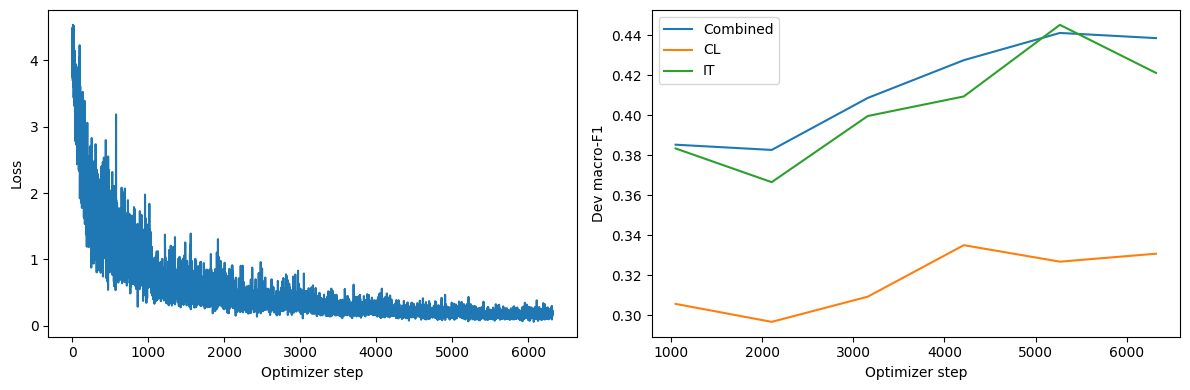

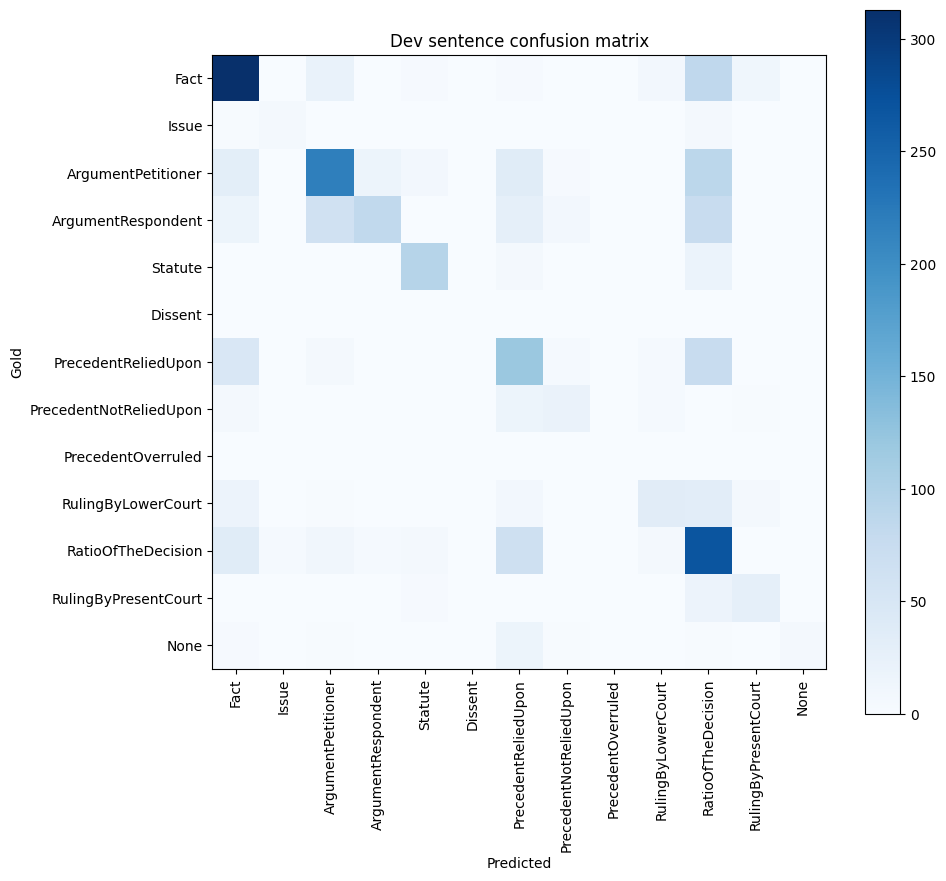

Predicting test:   0%|          | 0/550 [00:00<?, ?batch/s]

Verification PASS. Saved: /content/drive/MyDrive/cs781_phase3/lightweight_kd_kd_context2/submission.zip
lightweight_kd — official DEV
Macro-F1 [PRIMARY]: 0.441058; Macro-Precision: 0.520823; Macro-Recall: 0.417722
Label                         Precision     Recall         F1     Gold
Fact                             0.6631     0.7050     0.6834      444
Issue                            0.5385     0.4667     0.5000       15
ArgumentPetitioner               0.6760     0.5425     0.6019      400
ArgumentRespondent               0.8039     0.3015     0.4385      272
Statute                          0.8087     0.7750     0.7915      120
Dissent                          0.0000     0.0000     0.0000        0
PrecedentReliedUpon              0.3967     0.4685     0.4296      254
PrecedentNotReliedUpon           0.5263     0.4000     0.4545       50
PrecedentOverruled               0.0000     0.0000     0.0000        0
RulingByLowerCourt               0.6034     0.3431     0.4375      102
Ratio

In [ ]:
selected_experiments=list(EXPERIMENTS) if RUN_ALL else [EXPERIMENT]
results=[]
for name in tqdm(selected_experiments,desc='RR experiments',unit='run'):
    results.append(run_experiment(name))
for name in selected_experiments:
    output=run_path(name)
    metrics=json.loads((output/'metrics.json').read_text())
    show_scores(metrics,name+' — official DEV')
    print('Verification:',json.loads((output/'verification.json').read_text()))
    with zipfile.ZipFile(output/'submission.zip') as archive:
        assert archive.namelist()==['prediction.json']
        predictions=json.loads(archive.read('prediction.json'))
    validate_predictions(predictions,DATA['test'])
    assert predictions==json.loads((output/'prediction.json').read_text())

## 13. How to tune and compare scores in Colab

Change variables **only in section 3**, then rerun from section 3 onward. Use a new run tag whenever
training settings change; for example `RUN_TAG='decoder_epochs10'`, `EPOCHS=10`, `RUN_ALL=False`.
A new run starts from the Phase 1 checkpoint and gets a new learning-rate schedule. It does not extend
an existing completed schedule. Keep `SEED` and the official train/dev split fixed for comparisons.

| Setting | What it tests | Suggested controlled comparison |
|---|---|---|
| `EXPERIMENT` | Architecture/adaptation method | First run full decoder; then run all six |
| `EPOCHS` | Training duration | Compare 6 vs 10 with dev-selected checkpoint/early stopping |
| `EXPERIMENTS[name]['lr']` | Backbone/adapter learning rate | Vary one run at a time; record dev scores |
| `HEAD_LR_MULTIPLIER` | Learning speed of new head/domain/position features | Compare 3 vs 5 |
| `CONTEXT_SENTENCES` | Surrounding sentence context | Compare 0 vs 1 vs 2 |
| `MAX_LENGTH`, `MAX_TARGET_TOKENS` | Context/target retention | Compare 384/256 vs 512/320; inspect truncation counts |
| `BATCH_SIZE`, `GRAD_ACCUM_STEPS` | Memory and effective batch | Product is sentences per optimizer step; new tag required |
| `USE_CLASS_WEIGHTS`, `CLASS_WEIGHT_POWER` | Rare-role sensitivity | Compare unweighted vs power 0.5; inspect Dissent/PrecedentOverruled |
| `ADAPTER_RANK`, `ADAPTER_ALPHA` | PEFT capacity/scaling | New tag; never treat rank changes as new methods |
| `KD_WEIGHT`, `KD_TEMPERATURE` | Teacher/student tradeoff | KD teacher requires matching run configuration |
| `OPTIMIZE_DECODING` | Sentence-transition smoothing | Compare selected dev F1 with saved argmax baseline |

Start with one run to confirm official schema and actual dev performance, then use `RUN_ALL=True`
for coverage. Change **one factor at a time** and keep `run_config.json` and metrics together.
Higher dev F1 after repeated tuning may overestimate generalization; official test labels remain private.
Do not tune against invented test scores. The decoder search only changes postprocessing, not training.
If memory runs out, reduce batch size and increase accumulation for a fresh run tag.

Outputs are saved under `MyDrive/cs781_phase3/<experiment>_<RUN_TAG>/`: `last.pt`, `best_model.pt`,
`run_config.json`, `model_metadata.json`, `history.json`, `best_dev_metrics.json`, `best_selection_metrics.json`, `metrics.json`,
`per_label_metrics.csv`, `dev_prediction.json`, `dev_errors.json`, `decoder_config.json`,
`decoding_candidates.json`, `training_curves.png`, `confusion_matrix.png`, `verification.json`,
`prediction.json`, and `submission.zip`. The shared tokenizer and dataset manifest are at the root.
After a disconnect rerun with identical settings; unsaved steps after the last checkpoint may repeat.

## 14. Experiment coverage and source references

In [ ]:
summary=[]
for name in EXPERIMENTS:
    path=run_path(name)/'metrics.json'
    if path.is_file():
        m=json.loads(path.read_text())
        summary.append({k:m[k] for k in ['experiment','architecture','method','macro_f1',
            'macro_precision','macro_recall','baseline_macro_f1','total_parameters','trainable_parameters','training_complete']})
if summary:
    import csv
    with open(PROJECT_DIR/f'experiment_summary_{RUN_TAG}.csv','w',newline='',encoding='utf-8') as f:
        writer=csv.DictWriter(f,fieldnames=list(summary[0])); writer.writeheader(); writer.writerows(summary)
    for row in summary:
        print(row['experiment'],f"F1={row['macro_f1']:.6f}", 'completed=',row['training_complete'])
completed=[r for r in summary if r['training_complete']]
prediction_digests={}
for row in completed:
    path=run_path(row['experiment'])/'prediction.json'
    if path.is_file():
        canonical=json.dumps(json.loads(path.read_text()),sort_keys=True).encode()
        prediction_digests[row['experiment']]=hashlib.sha256(canonical).hexdigest()
methods={r['method'] for r in completed}
coverage={'six_completed':len(completed)>=6,
    'six_distinct_prediction_files':len(set(prediction_digests.values()))>=6,
    'all_four_phase1_origins':{r['architecture'] for r in completed}==set(MODEL_CLASSES),
    'four_listed_techniques':len(methods & {'lora','rslora','lorma','ia3','kd'})>=4,
    'three_adaptation_methods':len(methods-{'full','kd'})>=3,
    'lorma_completed':'lorma' in methods,'kd_completed':'kd' in methods,
    'all_completed_archives_exist':all((run_path(r['experiment'])/'submission.zip').is_file() for r in completed)}
save_json(coverage,PROJECT_DIR/f'coverage_{RUN_TAG}.json')
print('Coverage (does not prove Codabench acceptance):',coverage)

lightweight_lorma F1=0.415676 completed= True
lightweight_kd F1=0.441058 completed= True
Coverage (does not prove Codabench acceptance): {'six_completed': False, 'six_distinct_prediction_files': False, 'all_four_phase1_origins': False, 'four_listed_techniques': False, 'three_adaptation_methods': False, 'lorma_completed': True, 'kd_completed': True, 'all_completed_archives_exist': True}


References: local `Capstone Document_edited.pdf` §§1, 9, 19; professor's Phase 1 starter for workflow;
your Phase 1 solution for checkpoint-compatible definitions; the Phase 2 implementation for verified
checkpoint/RNG handling. Cite these and disclose coding assistance in your course deliverables.

- [LoRA](https://arxiv.org/abs/2106.09685).
- [rsLoRA](https://arxiv.org/abs/2312.03732): alpha/sqrt(rank) scaling.
- [LoRMA](https://aclanthology.org/2025.findings-acl.527/): additive rank inflation, Eq. 8.
- [IA³](https://arxiv.org/abs/2205.05638): trainable key/value and FF intermediate scaling vectors.
- [Knowledge distillation](https://arxiv.org/abs/1503.02531).

The notebook implements a modest train-fitted transition decoder; it is not a trained CRF or a claim
of state-of-the-art performance. Inspect actual dev errors before deciding which change helps.